In [1]:
%pip -q install scikit-learn vaderSentiment nltk wordcloud

In [2]:
from collections import Counter
from html import unescape
from pathlib import Path
import re
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from nltk import download, pos_tag_sents
from nltk.stem import PorterStemmer, WordNetLemmatizer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from wordcloud import WordCloud

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_colwidth", 130)
pd.set_option("display.max_columns", 30)
ROOT = Path.cwd()
try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    files = None
    IN_COLAB = False

raw_candidates = [ROOT / "Tweets.csv", ROOT / "dataset" / "Tweets.csv"]
RAW_PATH = next((path for path in raw_candidates if path.exists()), None)
if RAW_PATH is None and IN_COLAB:
    uploaded = files.upload()
    uploaded_csvs = [Path(name) for name in uploaded if Path(name).name.lower() == "tweets.csv"]
    if not uploaded_csvs:
        raise FileNotFoundError("Upload the supplied Tweets.csv file to continue.")
    RAW_PATH = uploaded_csvs[0]
if RAW_PATH is None:
    raise FileNotFoundError("Place Tweets.csv beside this notebook or upload it in Google Colab.")
OUT_DIR = ROOT / "dataset"
OUT_DIR.mkdir(exist_ok=True)

df = pd.read_csv(RAW_PATH)
df["text"] = df["text"].fillna("").astype(str)
df["airline_sentiment"] = df["airline_sentiment"].str.lower()
df["tweet_created"] = pd.to_datetime(df["tweet_created"], errors="coerce", utc=True)
print(f"Loaded {len(df):,} tweets from {RAW_PATH.name}")
display(df[["airline", "airline_sentiment", "airline_sentiment_confidence", "text"]].head())
print("\nHuman labels:\n", df["airline_sentiment"].value_counts())
print("\nAirline counts:\n", df["airline"].value_counts())

Saving Tweets.csv to Tweets.csv
Loaded 14,640 tweets from Tweets.csv


,airline,airline_sentiment,airline_sentiment_confidence,text
0,Virgin America,neutral,1.0000,@VirginAmerica What @dhepburn said.
1,Virgin America,positive,0.3486,@VirginAmerica plus you've added commercials to the experience... tacky.
2,Virgin America,neutral,0.6837,@VirginAmerica I didn't today... Must mean I need to take another trip!
3,Virgin America,negative,1.0000,"@VirginAmerica it's really aggressive to blast obnoxious ""entertainment"" in your guests' faces &amp; they have little recourse"
4,Virgin America,negative,1.0000,@VirginAmerica and it's a really big bad thing about it



Human labels:
 airline_sentiment
negative    9178
neutral     3099
positive    2363
Name: count, dtype: int64

Airline counts:
 airline
United            3822
US Airways        2913
American          2759
Southwest         2420
Delta             2222
Virgin America     504
Name: count, dtype: int64


## Part A — What text cleaning does (and costs)

A regex tokenizer is intentionally used as a transparent baseline. Mentions
and URLs are removed; `#` is removed but its word is retained; HTML entities
are decoded; stretched words are shortened; common contractions are expanded.
A few recurring injected label artifacts ("Cancelled Flighted", "Late Flightr")
are normalized conservatively. Negators (`not`, `no`, `nor`) are retained.
A small emoji map preserves common positive/negative emoji as tokens; unknown
emoji are dropped, so this is not a comprehensive emoji sentiment model.

In [3]:
CONTRACTIONS = {
    "can't": "can not", "won't": "will not", "n't": " not",
    "'re": " are", "'ve": " have", "'ll": " will", "'m": " am",
    "'d": " would",
}
BASE_STOP = set("""
a an the and or but if while with of at by for from in into on onto to up
about above after again against all am any are as be because been before
being below between both can could did do does doing down during each few
further had has have having he her here hers herself him himself his how is
i it its itself just me more most my myself once only other our ours
ourselves out over own same she should so some such than then there these
they this those through too under until very was we were what when where
which who whom why will would you your yours yourself yourselves that t
not no nor
""".split())
NEGATORS = {"not", "no", "nor"}
STOP_WORDS = BASE_STOP - NEGATORS
AIRLINE_NOISE = {"united", "american", "delta", "southwest", "virgin",
                 "america", "us", "airways", "jetblue"}
TOKEN_RE = re.compile(r"[a-z]+(?:'[a-z]+)?")
EMOJI_WORDS = {
    "😊": " emoji_positive ", "😀": " emoji_positive ", "😍": " emoji_positive ",
    "❤️": " emoji_positive ", "😂": " emoji_positive ",
    "😞": " emoji_negative ", "😢": " emoji_negative ", "😭": " emoji_negative ",
    "😡": " emoji_negative ",
}

def expand_contractions(text):
    text = text.lower()
    text = re.sub(r"\bcan't\b", "can not", text)
    text = re.sub(r"\bwon't\b", "will not", text)
    text = re.sub(r"n't\b", " not", text)
    for suffix, replacement in CONTRACTIONS.items():
        if suffix.startswith("'"):
            text = re.sub(re.escape(suffix) + r"\b", replacement, text)
    return text

def tokenize(text):
    text = unescape(str(text))
    text = re.sub(r"\bcancelled\s+flight(?:ed|led)\b", "cancelled", text, flags=re.I)
    text = re.sub(r"\blate\s+flight(?:r|ed|led)\b", "late", text, flags=re.I)
    for symbol, word in EMOJI_WORDS.items():
        text = text.replace(symbol, word)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text, flags=re.I)
    text = re.sub(r"@\w+", " ", text)
    text = text.replace("#", "")
    text = re.sub(r"([a-z])\1{2,}", r"\1\1", text, flags=re.I)
    text = expand_contractions(text)
    return TOKEN_RE.findall(text)

def clean_tokens(text, remove_stop=True, remove_airline=True):
    tokens = tokenize(text)
    if remove_stop:
        tokens = [w for w in tokens if w not in STOP_WORDS]
    if remove_airline:
        tokens = [w for w in tokens if w not in AIRLINE_NOISE]
    return tokens

def naive_tokens(text):
    return re.findall(r"\w+", text)

examples = [
    "@United #Delayed flight at https://example.com",
    "Sooooo happy!!! 😊",
    "I can't say it was not good",
    "I waited for hours 😡",
    "Cancelled Flighted our flight; 3 hours Late Flightr",
]
display(pd.DataFrame({
    "tweet feature": examples,
    "naive tokenizer": [naive_tokens(x) for x in examples],
    "chosen tokenizer": [tokenize(x) for x in examples],
}))

corpus_raw = df["text"].tolist()
tok_basic = [tokenize(t) for t in corpus_raw]
tok_no_stops = [[w for w in t if w not in BASE_STOP] for t in tok_basic]
tok_final = [clean_tokens(t) for t in corpus_raw]
stemmer = PorterStemmer()
if not download("wordnet", quiet=True):
    raise RuntimeError("NLTK WordNet corpus is required; run nltk.download('wordnet').")
if not download("averaged_perceptron_tagger_eng", quiet=True):
    raise RuntimeError("NLTK English POS tagger is required; run nltk.download('averaged_perceptron_tagger_eng').")
lemmatizer = WordNetLemmatizer()
vocab_examples = [
    ("delayed", "v"), ("delays", "v"), ("delaying", "v"),
    ("cancelled", "v"), ("cancellations", "n"),
    ("flies", "v"), ("flying", "v"), ("better", "a"), ("worse", "a"),
]
stem_lemma = pd.DataFrame({
    "word": [w for w, pos in vocab_examples],
    "POS": [pos for w, pos in vocab_examples],
    "Porter stem": [stemmer.stem(w) for w, pos in vocab_examples],
    "WordNet lemma": [lemmatizer.lemmatize(w, pos) for w, pos in vocab_examples],
})
display(stem_lemma)

def metrics(token_lists):
    flat = [w for row in token_lists for w in row]
    return {
        "vocabulary size": len(set(flat)),
        "mean tokens/tweet": np.mean([len(row) for row in token_lists]),
        "tweets empty": sum(not row for row in token_lists),
    }

raw_tokens = [naive_tokens(t.lower()) for t in corpus_raw]
preprocessed = pd.DataFrame([
    {"step": "Naive raw tokens", **metrics(raw_tokens)},
    {"step": "URLs/handles/HTML/entities + contraction/stretch normalization", **metrics(tok_basic)},
    {"step": "Common stop words removed; negators kept", **metrics(tok_no_stops)},
    {"step": "Stop words + airline-name noise removed (analysis tokens)", **metrics(tok_final)},
])
display(preprocessed)
negation_demo = pd.DataFrame({
    "original": ["The flight was good", "The flight was not good", "No delay, nor cancellation"],
})
negation_demo["with negators"] = negation_demo["original"].map(lambda x: " ".join(w for w in tokenize(x) if w not in STOP_WORDS))
negation_demo["standard list (negators removed)"] = negation_demo["original"].map(lambda x: " ".join(w for w in tokenize(x) if w not in BASE_STOP))
demo_analyzer = SentimentIntensityAnalyzer()
negation_demo["VADER w/ negators"] = negation_demo["with negators"].map(
    lambda x: demo_analyzer.polarity_scores(x)["compound"])
negation_demo["VADER w/o negators"] = negation_demo["standard list (negators removed)"].map(
    lambda x: demo_analyzer.polarity_scores(x)["compound"])
display(negation_demo)
artifact_count = df["text"].str.count(
    r"(?i)\bcancelled\s+flight(?:ed|led)\b|\blate\s+flight(?:r|ed|led)\b").sum()
print(f"Normalized {artifact_count:,} recurring injected label artifacts (Cancelled Flighted / Late Flightr variants).")

print("Vocab before stemming:", len(set(w for row in tok_final for w in row)))
stemmed_vocab = {stemmer.stem(w) for row in tok_final for w in row}
tagged_tokens = pos_tag_sents(tok_final)
lemma_vocab = {
    lemmatizer.lemmatize(word, {"J": "a", "V": "v", "N": "n", "R": "r"}.get(tag[0], "n"))
    for row in tagged_tokens for word, tag in row
}
print("Vocab after Porter stemming:", len(stemmed_vocab))
print("Vocab after WordNet lemmatization:", len(lemma_vocab))
print("Stemming is more aggressive (e.g. 'delay'/'delayed' collapse), while lemmatization is more readable.")

,tweet feature,naive tokenizer,chosen tokenizer
0,@United #Delayed flight at https://example.com,"[United, Delayed, flight, at, https, example, com]","[delayed, flight, at]"
1,Sooooo happy!!! 😊,"[Sooooo, happy]","[soo, happy, emoji, positive]"
2,I can't say it was not good,"[I, can, t, say, it, was, not, good]","[i, can, not, say, it, was, not, good]"
3,I waited for hours 😡,"[I, waited, for, hours]","[i, waited, for, hours, emoji, negative]"
4,Cancelled Flighted our flight; 3 hours Late Flightr,"[Cancelled, Flighted, our, flight, 3, hours, Late, Flightr]","[cancelled, our, flight, hours, late]"


,word,POS,Porter stem,WordNet lemma
0,delayed,v,delay,delay
1,delays,v,delay,delay
2,delaying,v,delay,delay
3,cancelled,v,cancel,cancel
4,cancellations,n,cancel,cancellation
5,flies,v,fli,fly
6,flying,v,fli,fly
7,better,a,better,good
8,worse,a,wors,bad


,step,vocabulary size,mean tokens/tweet,tweets empty
0,Naive raw tokens,15089,18.354713,0
1,URLs/handles/HTML/entities + contraction/stretch normalization,11264,16.281216,0
2,Common stop words removed; negators kept,11143,8.750956,21
3,Stop words + airline-name noise removed (analysis tokens),11137,9.005260,18


,original,with negators,standard list (negators removed),VADER w/ negators,VADER w/o negators
0,The flight was good,flight good,flight good,0.4404,0.4404
1,The flight was not good,flight not good,flight good,-0.3412,0.4404
2,"No delay, nor cancellation",no delay nor cancellation,delay cancellation,0.2411,-0.3182


Normalized 891 recurring injected label artifacts (Cancelled Flighted / Late Flightr variants).
Vocab before stemming: 11137
Vocab after Porter stemming: 8486
Vocab after WordNet lemmatization: 9546
Stemming is more aggressive (e.g. 'delay'/'delayed' collapse), while lemmatization is more readable.


## Part B — Word and phrase evidence

Airline names dominate raw words because tweets are replies/mentions directed
at the named carrier. We therefore remove handles, airline names and general
filler for theme discovery, but keep both raw counts and cleaned counts as an
audit trail. TF-IDF below compares class-level average TF-IDF, not raw totals.

Raw frequent tokens: [('to', 8652), ('i', 6703), ('the', 6061), ('a', 4514), ('you', 4401), ('united', 4164), ('for', 3999), ('flight', 3939), ('on', 3815), ('and', 3733), ('t', 3350), ('my', 3288), ('usairways', 3053), ('americanair', 2964), ('is', 2830)]
Filtered frequent tokens: [('flight', 3950), ('not', 3664), ('no', 1509), ('get', 1342), ('thanks', 1083), ('cancelled', 1065), ('now', 1037), ('service', 967), ('help', 873), ('time', 794), ('customer', 756), ('hours', 684), ('flights', 649), ('hold', 644), ('plane', 633)]


,term,positive_mean_tfidf,negative_mean_tfidf
1496,thanks,0.095243,0.007550
1495,thank,0.086385,0.002331
664,great,0.036199,0.002642
889,love,0.021550,0.001958
125,awesome,0.019086,0.000682
988,much,0.019382,0.003112
153,best,0.017777,0.002153
57,amazing,0.012831,0.000555
660,good,0.016701,0.004590
85,appreciate,0.011612,0.001632


,term,positive_mean_tfidf,negative_mean_tfidf
1023,not,0.012897,0.051568
1015,no,0.006198,0.028521
577,flight,0.026737,0.048235
206,cancelled,0.003458,0.022732
731,hours,0.000700,0.018159
715,hold,0.000828,0.018059
377,delayed,0.001754,0.014828
643,get,0.010481,0.022632
730,hour,0.001759,0.013873
200,call,0.002214,0.013339


,phrase,count
89,customer service,450
342,it s,356
48,cancelled flight,258
357,late flight,228
159,flight cancelled,198
496,not get,171
703,that s,162
454,no one,126
682,still not,112
168,flight delayed,111


,phrase,VADER compound
0,good,0.4404
1,not good,-0.3412


Operational phrase candidates: [{'phrase': 'customer service', 'count': 450}, {'phrase': 'cancelled flight', 'count': 258}, {'phrase': 'late flight', 'count': 228}, {'phrase': 'flight delayed', 'count': 111}]


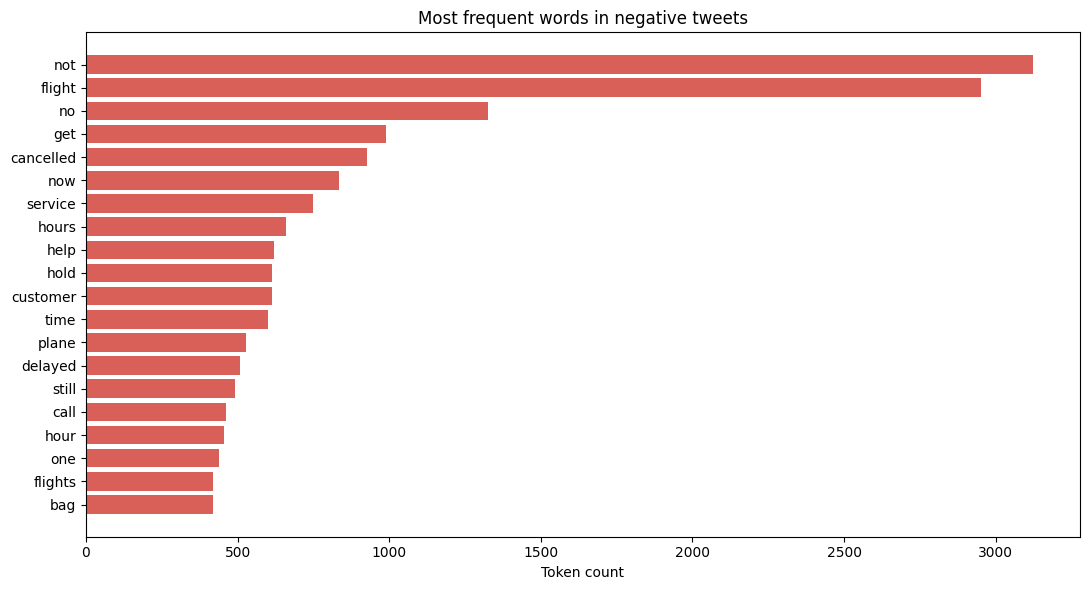

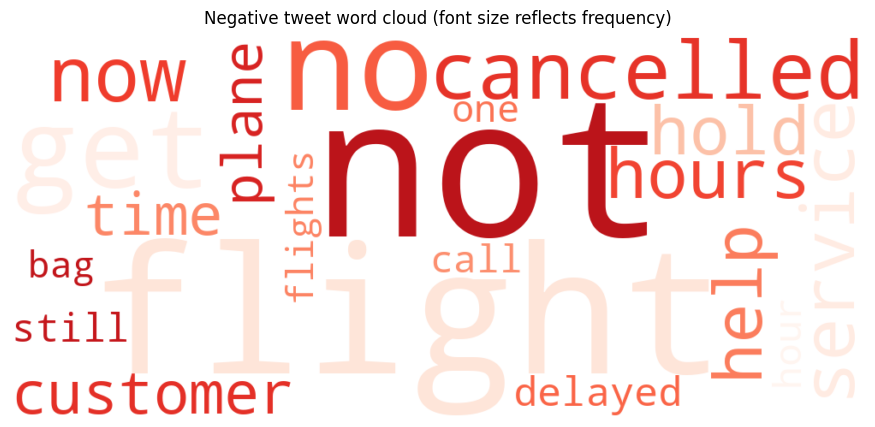

For a Director, prefer the bar chart: exact counts and rank are comparable; the cloud is an exploratory overview.


In [4]:
raw_counts = Counter(w for row in raw_tokens for w in row)
analysis_counts = Counter(w for row in tok_final for w in row)
print("Raw frequent tokens:", raw_counts.most_common(15))
print("Filtered frequent tokens:", analysis_counts.most_common(15))

df["analysis_text"] = [" ".join(x) for x in tok_final]
df["clean_text"] = [" ".join(tokenize(t)) for t in df["text"]]
tfidf = TfidfVectorizer(min_df=10, max_features=10000, token_pattern=r"(?u)\b\w+\b")
X = tfidf.fit_transform(df["analysis_text"])
terms = np.array(tfidf.get_feature_names_out())
class_tfidf = {}
for label in ["negative", "neutral", "positive"]:
    class_mask = df["airline_sentiment"].eq(label).to_numpy()
    class_tfidf[label] = np.asarray(X[class_mask].mean(axis=0)).ravel()
contrast = pd.DataFrame({
    "term": terms,
    "positive_mean_tfidf": class_tfidf["positive"],
    "negative_mean_tfidf": class_tfidf["negative"],
})
contrast["positive_minus_negative"] = contrast["positive_mean_tfidf"] - contrast["negative_mean_tfidf"]
display(contrast.nlargest(12, "positive_minus_negative")[["term", "positive_mean_tfidf", "negative_mean_tfidf"]])
display(contrast.nsmallest(12, "positive_minus_negative")[["term", "positive_mean_tfidf", "negative_mean_tfidf"]])

neg_docs = df.loc[df["airline_sentiment"].eq("negative"), "analysis_text"]
ngram_vec = CountVectorizer(ngram_range=(2, 3), min_df=8, token_pattern=r"(?u)\b\w+\b")
ngram_matrix = ngram_vec.fit_transform(neg_docs)
ngram_counts = np.asarray(ngram_matrix.sum(axis=0)).ravel()
ngram_terms = np.array(ngram_vec.get_feature_names_out())
top_ngrams = pd.DataFrame({"phrase": ngram_terms, "count": ngram_counts}).nlargest(20, "count")
display(top_ngrams)
part_flip = pd.DataFrame({
    "phrase": ["good", "not good"],
    "VADER compound": [
        demo_analyzer.polarity_scores("good")["compound"],
        demo_analyzer.polarity_scores("not good")["compound"],
    ],
})
display(part_flip)
print("Operational phrase candidates:", top_ngrams[top_ngrams["phrase"].str.contains(
    r"customer service|late flight|cancelled flight|lost luggage|flight delay|missed connection", case=False
)].head(8).to_dict("records"))

top_negative = Counter(w for row, label in zip(tok_final, df["airline_sentiment"])
                       if label == "negative" for w in row).most_common(20)
fig, ax = plt.subplots(figsize=(11, 6))
words, counts = zip(*top_negative)
ax.barh(words[::-1], counts[::-1], color="#d95f59")
ax.set(title="Most frequent words in negative tweets", xlabel="Token count")
plt.tight_layout()
plt.show()
cloud = WordCloud(width=1000, height=450, background_color="white", colormap="Reds",
                  collocations=False, random_state=11).generate_from_frequencies(dict(top_negative))
plt.figure(figsize=(12, 5))
plt.imshow(cloud, interpolation="bilinear")
plt.axis("off")
plt.title("Negative tweet word cloud (font size reflects frequency)")
plt.show()
print("For a Director, prefer the bar chart: exact counts and rank are comparable; the cloud is an exploratory overview.")

## Part C — Lexicon sentiment vs. human labels

VADER is applied to each original tweet. Its standard compound thresholds
(>= 0.05 positive, <= -0.05 negative, otherwise neutral) are fixed in advance.
Accuracy is reported with per-class recall and a confusion matrix because
class imbalance makes overall accuracy alone misleading.

In [5]:
analyzer = demo_analyzer
vader_scores = df["text"].map(analyzer.polarity_scores)
df["vader_compound"] = vader_scores.map(lambda x: x["compound"])
df["vader_sentiment"] = df["vader_compound"].map(
    lambda x: "positive" if x >= 0.05 else ("negative" if x <= -0.05 else "neutral")
)
labels = ["negative", "neutral", "positive"]
print("All-label accuracy:", round(accuracy_score(df["airline_sentiment"], df["vader_sentiment"]), 4))
print(classification_report(df["airline_sentiment"], df["vader_sentiment"], labels=labels, zero_division=0))
display(pd.DataFrame(confusion_matrix(df["airline_sentiment"], df["vader_sentiment"], labels=labels),
                     index=[f"human {x}" for x in labels],
                     columns=[f"VADER {x}" for x in labels]))

conf_col = "airline_sentiment_confidence"
high_conf = df[conf_col].fillna(0).ge(0.8)
print(f"Confidence >= 0.8: {high_conf.sum():,}/{len(df):,} tweets; accuracy = "
      f"{accuracy_score(df.loc[high_conf, 'airline_sentiment'], df.loc[high_conf, 'vader_sentiment']):.3f}")
display(df.groupby("airline_sentiment")[conf_col].agg(["count", "mean", "median"]))

def stopword_variant(text, remove_negators):
    words = tokenize(text)
    stop = BASE_STOP if remove_negators else STOP_WORDS
    return " ".join(w for w in words if w not in stop)

with_negators = df["text"].map(lambda x: analyzer.polarity_scores(stopword_variant(x, False))["compound"])
without_negators = df["text"].map(lambda x: analyzer.polarity_scores(stopword_variant(x, True))["compound"])
negation_comparison = pd.DataFrame({
    "version": ["Original VADER input", "Common stop words removed; negators kept",
                "Common stop words removed; negators also removed"],
    "accuracy": [
        accuracy_score(df["airline_sentiment"], df["vader_sentiment"]),
        accuracy_score(df["airline_sentiment"], with_negators.map(lambda x: "positive" if x >= .05 else ("negative" if x <= -.05 else "neutral"))),
        accuracy_score(df["airline_sentiment"], without_negators.map(lambda x: "positive" if x >= .05 else ("negative" if x <= -.05 else "neutral"))),
    ],
})
display(negation_comparison)

errors = df[df["airline_sentiment"] != df["vader_sentiment"]].copy()
def disagreement_cause(text):
    t = text.lower()
    if re.search(r"\b(thanks|great|awesome|love|wonderful)\b.*\b(delay|wait|cancel|again|sarcasm)\b", t):
        return "sarcasm / ironic praise"
    if re.search(r"\b(not|no|never|n't|cannot|can't)\b", t):
        return "negation"
    if re.search(r"\b(but|however|although|though)\b", t):
        return "mixed feelings"
    if re.search(r"\b(delay|delayed|cancel|cancelled|late|lost|missed|luggage|bag)\b", t):
        return "airline operational vocabulary"
    return "other context / lexicon or label ambiguity"
errors["likely_cause"] = errors["text"].map(disagreement_cause)
cause_counts = errors["likely_cause"].value_counts().rename_axis("heuristic cause").to_frame("disagreements")
display(cause_counts)
human_polarity = df["airline_sentiment"].map({"negative": -1, "neutral": 0, "positive": 1})
errors["polarity_gap"] = (errors["vader_compound"] - human_polarity.loc[errors.index]).abs()
display(errors.sort_values("polarity_gap", ascending=False)
        [["airline", "airline_sentiment", "vader_sentiment", "vader_compound",
          "airline_sentiment_confidence", "polarity_gap", "text"]].head(12))
print("Largest heuristic cause:", cause_counts.index[0],
      "— address with a local airline lexicon and human-reviewed disagreement samples.")

custom_examples = pd.DataFrame({"tweet": [
    "Great, another three-hour delay. Exactly what I wanted.",
    "The service was not good, but the agent was kind.",
    "I love waiting on hold for two hours.",
]})
custom_examples["VADER compound"] = custom_examples["tweet"].map(
    lambda x: analyzer.polarity_scores(x)["compound"])
custom_examples["VADER label"] = custom_examples["VADER compound"].map(
    lambda x: "positive" if x >= .05 else ("negative" if x <= -.05 else "neutral"))
custom_examples["why word counting misleads"] = [
    "Positive-sounding words are sarcastic in context.",
    "Mixed clauses pull in opposite directions; a single label loses nuance.",
    "Positive 'love' is ironic; no reliable sarcasm cue is present.",
]
display(custom_examples)

All-label accuracy: 0.4899
              precision    recall  f1-score   support

    negative       0.90      0.44      0.59      9178
     neutral       0.39      0.32      0.35      3099
    positive       0.28      0.91      0.43      2363

    accuracy                           0.49     14640
   macro avg       0.52      0.56      0.46     14640
weighted avg       0.69      0.49      0.51     14640



,VADER negative,VADER neutral,VADER positive
human negative,4033,1427,3718
human neutral,363,989,1747
human positive,68,145,2150


Confidence >= 0.8: 10,459/14,640 tweets; accuracy = 0.531


,count,mean,median
airline_sentiment,,,
negative,9178,0.933365,1.000
neutral,3099,0.823303,0.916
positive,2363,0.872039,1.000


,version,accuracy
0,Original VADER input,0.489891
1,Common stop words removed; negators kept,0.543238
2,Common stop words removed; negators also removed,0.503415


,disagreements
heuristic cause,
other context / lexicon or label ambiguity,4397
negation,1693
airline operational vocabulary,867
mixed feelings,472
sarcasm / ironic praise,39


,airline,airline_sentiment,vader_sentiment,vader_compound,airline_sentiment_confidence,polarity_gap,text
5947,Southwest,negative,positive,0.9716,1.0000,1.9716,@SouthwestAir Report was filed but would like to support some active searching. Feels pretty passive now. Info on computer i...
13794,American,negative,positive,0.9712,1.0000,1.9712,@AmericanAir that luggage you forgot...#mia.....he just won an oscar😄💝💝💝
2854,United,negative,positive,0.9607,1.0000,1.9607,@united MIA-EWR #384 😄😄😄 excellent crew. EWR-IAD #3589 😡😡😡 No crew to load bags - waiting w/ door open freezing. 20 mins past ...
2437,United,negative,positive,0.9595,1.0000,1.9595,@united What a really GREAT &amp; FLATTERING story about you! You should be very proud :) http://t.co/oKtUkjY92O (via @Parachu...
2720,United,negative,positive,0.9555,1.0000,1.9555,"@united Your ""Loyalty Team"" basically flipped me off via phone, but thanks. Maybe Google ""loyalty"" and get back to me? ^LOL"
11702,US Airways,positive,negative,-0.9517,1.0000,1.9517,"@USAirways YOU ARE THE BEST AIRWAYS!!!!!!!!!! FOLLOW ME BACK, PLEASE 🙏🙏🙏🙏🙏🙏🙏🙏🙏🙏🙏😢😢😢😢😢😢😢😢🙏🙏🙏🙏🙏🙏🙏🙏🙏🙏🙏🙏🙏🙏🙏🙏🙏🙏🙏🙏🙏"
752,United,negative,positive,0.9403,0.3579,1.9403,@united The bright side would be keeping the promise that was made to me. Hope you're having a good night. Thanks.
4966,Southwest,negative,positive,0.9384,0.6700,1.9384,@SouthwestAir now I'm so lucky for my forced good deed I get to be smashed between 2 huge ppl in the exit row. Thank God I'm t...
1936,United,negative,positive,0.9348,1.0000,1.9348,@united they wouldn't let me on. Real nice of you! Just love your awesome service. And U have 2 people working this customer s...
7244,Delta,negative,positive,0.9331,1.0000,1.9331,@JetBlue not an issue but I think training &amp; information would help. Great ppl but service needs to switch from individual...


Largest heuristic cause: other context / lexicon or label ambiguity — address with a local airline lexicon and human-reviewed disagreement samples.


,tweet,VADER compound,VADER label,why word counting misleads
0,"Great, another three-hour delay. Exactly what I wanted.",0.4215,positive,Positive-sounding words are sarcastic in context.
1,"The service was not good, but the agent was kind.",0.5990,positive,Mixed clauses pull in opposite directions; a single label loses nuance.
2,I love waiting on hold for two hours.,0.6369,positive,Positive 'love' is ironic; no reliable sarcasm cue is present.


## Part D — Airline comparison, time and response priority

Shares are preferred for cross-airline comparisons because airline volumes
differ. These are associations in a short, self-selected social-media sample,
not causal estimates of service quality. The priority rule below is an
operational triage proposal, not a validated risk score.

airline_sentiment,negative,neutral,positive
airline,,,
American,71.0,16.8,12.2
Delta,43.0,32.5,24.5
Southwest,49.0,27.4,23.6
US Airways,77.7,13.1,9.2
United,68.9,18.2,12.9
Virgin America,35.9,33.9,30.2


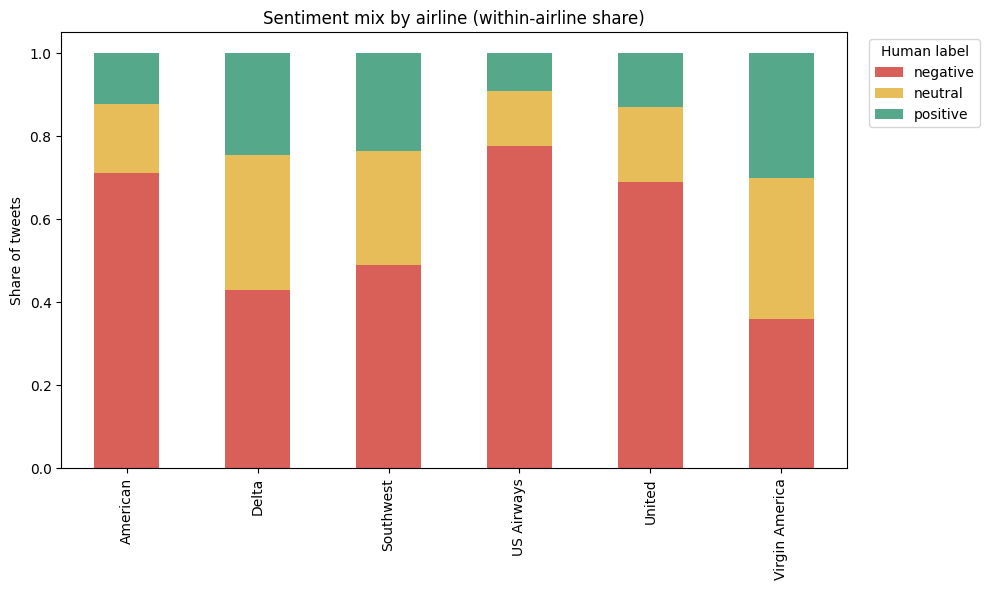

,negative tweets,customer-service share of coded reasons,operations share of coded reasons
airline,,,
United,2633,0.395,0.461
US Airways,2263,0.489,0.403
American,1960,0.520,0.379
Southwest,1186,0.438,0.428
Delta,955,0.332,0.473
Virgin America,181,0.530,0.348


Service-type share is highest for Virgin America (53.0% of coded reasons); operations-type share is highest for Delta (47.3%).
United has the largest raw negative count (2,633), but US Airways has the largest negative share (77.7%); report share for cross-airline comparison.


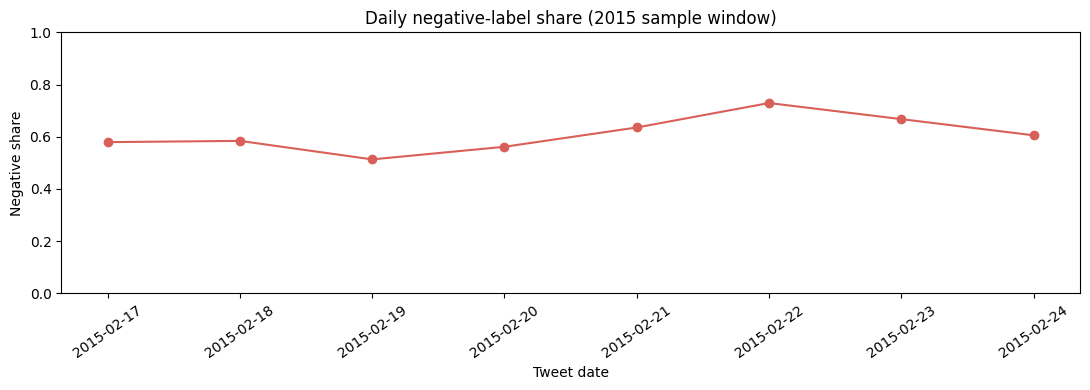

Observed date range: 2015-02-17 07:36:05+00:00 to 2015-02-24 19:53:37+00:00 (8 calendar days)


,airline,negativereason,airline_sentiment_confidence,retweet_count,priority_score,text
12680,American,Cancelled Flight,1.0,5,8.0,@AmericanAir Cancelled Flight my flight saying it is cause of weather condition when it was the only flight that was Cancelled...
11388,US Airways,Damaged Luggage,1.0,4,7.8,@USAirways @DRVRugby team is back home but luggage all wet and partly damaged - Not happy! #blizzard
12678,American,Cancelled Flight,1.0,4,7.8,@AmericanAir This is getting a bit ridiculous when and you have made me miss 2 full days off work and had to pay for cabs back...
12681,American,Cancelled Flight,1.0,4,7.8,@AmericanAir Again you guys are a huge joke and Cancelled Flight your flight for no reason. This is the 3rd time in one trip f...
6485,Southwest,Cancelled Flight,1.0,3,7.6,@SouthwestAir I have had 4 flights Cancelled Flightled through yall!!!! Im sick of it 😠😠
1107,United,Cancelled Flight,1.0,2,7.4,"@united Oh, we are sure it's not planned, but it occurs absolutely consistently, it's usually the only YYJ flight that's Cance..."
8209,Delta,Cancelled Flight,1.0,2,7.4,@JetBlue what's going on with flight 669 and how many free trips will I get from this epic inconvenience @anku http://t.co/pEU...
5226,Southwest,Cancelled Flight,1.0,2,7.4,@SouthwestAir flight to PHL from FLL Cancelled Flighted 2/21 no flight available until 2/24 done with SW.
5222,Southwest,Cancelled Flight,1.0,2,7.4,@SouthwestAir flight to PHL from FLL Cancelled Flighted 2/21 no flight available until 2/24 done with SW. They are a pain to d...
2664,United,Cancelled Flight,1.0,2,7.4,"@united first you lost all my bags, now you Cancelled Flight my flight home. 30 min wait to talk to somebody #poorservice #not..."


Proposed response rule: prioritize specific severe issues (cancellation/lost or damaged luggage), then high-confidence complaints and repeated/retweeted reports; route by issue type.


In [6]:
airline_sent = pd.crosstab(df["airline"], df["airline_sentiment"], normalize="index").reindex(
    columns=labels, fill_value=0)
display((airline_sent * 100).round(1))
fig, ax = plt.subplots(figsize=(10, 6))
airline_sent[labels].plot(kind="bar", stacked=True, ax=ax,
                          color=["#d95f59", "#e7bd5a", "#55a889"])
ax.set(title="Sentiment mix by airline (within-airline share)", ylabel="Share of tweets", xlabel="")
ax.legend(title="Human label", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

negative_df = df[df["airline_sentiment"].eq("negative")].copy()
reason_mix = pd.crosstab(negative_df["airline"], negative_df["negativereason"])
reason_share = reason_mix.div(reason_mix.sum(axis=1), axis=0)
service_reasons = ["Customer Service Issue", "Flight Attendant Complaints", "Flight Booking Problems", "longlines"]
ops_reasons = ["Late Flight", "Cancelled Flight", "Lost Luggage", "Damaged Luggage", "Bad Flight"]
airline_issue_mix = pd.DataFrame({
    "negative tweets": reason_mix.sum(axis=1),
    "customer-service share of coded reasons": reason_share.reindex(columns=service_reasons, fill_value=0).sum(axis=1),
    "operations share of coded reasons": reason_share.reindex(columns=ops_reasons, fill_value=0).sum(axis=1),
}).sort_values("negative tweets", ascending=False)
display(airline_issue_mix.round(3))
top_service = airline_issue_mix["customer-service share of coded reasons"].idxmax()
top_operations = airline_issue_mix["operations share of coded reasons"].idxmax()
top_raw_negative = airline_issue_mix["negative tweets"].idxmax()
top_negative_share = airline_sent["negative"].idxmax()
print(f"Service-type share is highest for {top_service} "
      f"({airline_issue_mix.loc[top_service, 'customer-service share of coded reasons']:.1%} of coded reasons); "
      f"operations-type share is highest for {top_operations} "
      f"({airline_issue_mix.loc[top_operations, 'operations share of coded reasons']:.1%}).")
print(f"{top_raw_negative} has the largest raw negative count "
      f"({int(airline_issue_mix.loc[top_raw_negative, 'negative tweets']):,}), but {top_negative_share} has the largest "
      f"negative share ({airline_sent.loc[top_negative_share, 'negative']:.1%}); report share for cross-airline comparison.")

daily = df.set_index("tweet_created").groupby(pd.Grouper(freq="D")).agg(
    tweets=("airline_sentiment", "size"),
    negative_share=("airline_sentiment", lambda s: s.eq("negative").mean()),
).dropna()
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(daily.index, daily["negative_share"], marker="o", color="#d95f59")
ax.set(title="Daily negative-label share (2015 sample window)", ylabel="Negative share", xlabel="Tweet date")
ax.set_ylim(0, 1)
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()
print("Observed date range:", df["tweet_created"].min(), "to", df["tweet_created"].max(),
      f"({df['tweet_created'].dt.date.nunique()} calendar days)")

def priority_score(row):
    reason = str(row.get("negativereason", ""))
    severity = 3 if reason in {"Cancelled Flight", "Lost Luggage", "Damaged Luggage"} else (
        2 if reason in {"Late Flight", "Customer Service Issue", "Bad Flight"} else 1)
    confidence = float(row.get("airline_sentiment_confidence", 0) or 0)
    engagement = min(int(row.get("retweet_count", 0) or 0), 5)
    return severity * 2 + confidence + engagement * 0.2

negative_df["priority_score"] = negative_df.apply(priority_score, axis=1)
priority_sample = negative_df.sort_values("priority_score", ascending=False).head(10)
display(priority_sample[["airline", "negativereason", "airline_sentiment_confidence",
                         "retweet_count", "priority_score", "text"]])
print("Proposed response rule: prioritize specific severe issues (cancellation/lost or damaged luggage), "
      "then high-confidence complaints and repeated/retweeted reports; route by issue type.")

## Part E — Limits and decision

* Twitter users are self-selected, not a passenger survey; highly motivated
  complainants and promoters are overrepresented.
* The sample is restricted to public tweets captured in a short 2015 window;
  airline policies, routes, products, and platform behavior have changed.
* Missing context, sarcasm, slang, negation, and mixed sentiment limit VADER.
* Human labels are imperfect too. The confidence field is annotator confidence,
  not a probability that the label is objectively correct.
* Many tweet locations are absent/ambiguous, and reply/retweet sampling can
  overrepresent a carrier or event. Complaint counts are not incident rates.

**Recommendation:** do not replace the reading team. Use automated charts and
sentiment as a fast queue/monitoring aid, then human-review high-impact cases
and sample disagreements. Recalibrate on contemporary, locally labeled data.

In [7]:
data_quality = pd.Series({
    "tweet location missing": df["tweet_location"].fillna("").eq("").mean(),
    "timezone missing": df["user_timezone"].fillna("").eq("").mean(),
    "zero retweets": pd.to_numeric(df["retweet_count"], errors="coerce").fillna(0).eq(0).mean(),
    "reason field blank (mostly non-negative)": df["negativereason"].fillna("").eq("").mean(),
})
display((100 * data_quality).round(1).rename("percent of records").to_frame())

negative_reason = negative_df["negativereason"].fillna("")
cant_tell_count = negative_reason.eq("Can't Tell").sum()
cant_tell_share = negative_reason.eq("Can't Tell").mean()
negative_tokens = negative_df["text"].str.findall(r"\b\w+\b").str.len()
positive_tokens = df.loc[df["airline_sentiment"].eq("positive"), "text"].str.findall(r"\b\w+\b").str.len()
print(f"'Can't Tell' is {cant_tell_count:,} of {len(negative_df):,} negative tweets "
      f"({cant_tell_share:.1%} of negatives).")
print(f"Median raw tweet length: negative={negative_tokens.median():.0f} tokens; "
      f"positive={positive_tokens.median():.0f} tokens.")
print(f"Tweets with zero retweets: {df['retweet_count'].fillna(0).eq(0).mean():.1%}.")

extra_insights = [
    {
        "Observation": "A sizeable slice of negative tweets is explicitly labeled 'Can't Tell' rather than a resolvable complaint type.",
        "Evidence": f"{cant_tell_count:,} of {len(negative_df):,} negative tweets ({cant_tell_share:.1%}).",
        "Why it matters": "Treating this code as an operational issue would misdirect the response; ignoring it hides uncertainty.",
        "Recommended action": "Second-pass review these tweets and distinguish unclear text from genuinely unclassified issue types.",
        "Confidence and limits": "High for the file's annotation; the category reflects annotator judgment, not verified cause.",
    },
    {
        "Observation": "Negative tweets are longer than positive tweets in this sample.",
        "Evidence": f"Median raw length: {negative_tokens.median():.0f} tokens negative vs. {positive_tokens.median():.0f} positive.",
        "Why it matters": "Longer complaints may carry multiple events and need context beyond a single sentiment score.",
        "Recommended action": "Keep full-text review in the queue for longer negative cases; do not use length as a severity proxy.",
        "Confidence and limits": "High for this dataset; tokenization and the 2015 sampling window affect the estimate.",
    },
    {
        "Observation": "Retweets are too sparse to use engagement alone as an urgency filter.",
        "Evidence": f"{df['retweet_count'].fillna(0).eq(0).mean():.1%} of tweets have zero retweets; median retweets are "
                    f"{df['retweet_count'].median():.0f}.",
        "Why it matters": "Quiet, potentially serious passenger cases would be missed by a popularity-first queue.",
        "Recommended action": "Prioritize issue severity and confidence first; use retweets only as a secondary signal.",
        "Confidence and limits": "High for recorded retweet counts; engagement is not a measure of passenger harm.",
    },
]
display(pd.DataFrame(extra_insights))

,percent of records
tweet location missing,32.3
timezone missing,32.9
zero retweets,94.8
reason field blank (mostly non-negative),37.3


'Can't Tell' is 1,190 of 9,178 negative tweets (13.0% of negatives).
Median raw tweet length: negative=22 tokens; positive=14 tokens.
Tweets with zero retweets: 94.8%.


,Observation,Evidence,Why it matters,Recommended action,Confidence and limits
0,A sizeable slice of negative tweets is explicitly labeled 'Can't Tell' rather than a resolvable complaint type.,"1,190 of 9,178 negative tweets (13.0%).",Treating this code as an operational issue would misdirect the response; ignoring it hides uncertainty.,Second-pass review these tweets and distinguish unclear text from genuinely unclassified issue types.,"High for the file's annotation; the category reflects annotator judgment, not verified cause."
1,Negative tweets are longer than positive tweets in this sample.,Median raw length: 22 tokens negative vs. 14 positive.,Longer complaints may carry multiple events and need context beyond a single sentiment score.,Keep full-text review in the queue for longer negative cases; do not use length as a severity proxy.,High for this dataset; tokenization and the 2015 sampling window affect the estimate.
2,Retweets are too sparse to use engagement alone as an urgency filter.,94.8% of tweets have zero retweets; median retweets are 0.,"Quiet, potentially serious passenger cases would be missed by a popularity-first queue.",Prioritize issue severity and confidence first; use retweets only as a secondary signal.,High for recorded retweet counts; engagement is not a measure of passenger harm.


## Export ? cleaned and scored dataset

Original columns are preserved. Added columns make the cleaning and model outputs inspectable. The cleaned file is saved under `dataset/` and downloaded in Colab.

In [8]:
df["analysis_tokens"] = [" ".join(t) for t in tok_final]
df["tweet_token_count"] = [len(t) for t in tok_final]
cleaned_path = OUT_DIR / "Tweets_cleaned.csv"
df.to_csv(cleaned_path, index=False, encoding="utf-8-sig")
print(f"Saved {len(df):,} rows to {cleaned_path}")
if IN_COLAB:
    files.download(str(cleaned_path))

Saved 14,640 rows to /content/dataset/Tweets_cleaned.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## One-page brief for the Director

In [9]:
from IPython.display import Markdown

negative_share = df["airline_sentiment"].eq("negative").mean()
major_reason = negative_df["negativereason"].value_counts().idxmax()
major_reason_count = int(negative_df["negativereason"].value_counts().max())
negative_recall = confusion_matrix(
    df["airline_sentiment"], df["vader_sentiment"], labels=labels
)[0, 0] / (df["airline_sentiment"].eq("negative").sum())
neutral_recall = confusion_matrix(
    df["airline_sentiment"], df["vader_sentiment"], labels=labels
)[1, 1] / (df["airline_sentiment"].eq("neutral").sum())
positive_recall = confusion_matrix(
    df["airline_sentiment"], df["vader_sentiment"], labels=labels
)[2, 2] / (df["airline_sentiment"].eq("positive").sum())

display(Markdown(f"""
# Customer voice: decisions from the 2015 tweet sample

**Bottom line:** automate monitoring and routing, not final sentiment decisions. The data is useful for surfacing themes quickly, but VADER agrees with the human label on only **{accuracy_score(df['airline_sentiment'], df['vader_sentiment']):.1%}** of tweets.

## What stands out
- **{negative_share:.1%}** of tweets are human-labeled negative. The largest coded negative reason is **{major_reason}** ({major_reason_count:,} tweets).
- **{top_negative_share}** has the highest negative share (**{airline_sent.loc[top_negative_share, 'negative']:.1%}**); **{top_raw_negative}** has the most negative tweets by count. Compare shares, not raw totals, across different airline volumes.
- Complaint mix differs: **{top_service}** has the highest service-type share ({airline_issue_mix.loc[top_service, 'customer-service share of coded reasons']:.1%}); **{top_operations}** has the highest operations-type share ({airline_issue_mix.loc[top_operations, 'operations share of coded reasons']:.1%}). Treat these as leads, not proof of relative service quality.
- VADER recall is **{negative_recall:.1%}** for negative, **{neutral_recall:.1%}** for neutral, and **{positive_recall:.1%}** for positive tweets. Neutral cases are hardest; overall accuracy hides this.

## What to do next
1. Route cancellations and lost/damaged luggage to operations; route service complaints to customer care.
2. Prioritize issue severity and label confidence. Retweets are sparse and should only be a secondary signal.
3. Keep people reviewing mixed, sarcastic, high-impact, and low-confidence tweets. Recalibrate with current, airline-specific examples before using automated scores operationally.

**Limits:** these public tweets are self-selected and span only eight days in February 2015. Tweet volume is not an incident rate, and the sample cannot establish causes or describe current airline performance.
"""))


# Customer voice: decisions from the 2015 tweet sample

**Bottom line:** automate monitoring and routing, not final sentiment decisions. The data is useful for surfacing themes quickly, but VADER agrees with the human label on only **49.0%** of tweets.

## What stands out
- **62.7%** of tweets are human-labeled negative. The largest coded negative reason is **Customer Service Issue** (2,910 tweets).
- **US Airways** has the highest negative share (**77.7%**); **United** has the most negative tweets by count. Compare shares, not raw totals, across different airline volumes.
- Complaint mix differs: **Virgin America** has the highest service-type share (53.0%); **Delta** has the highest operations-type share (47.3%). Treat these as leads, not proof of relative service quality.
- VADER recall is **43.9%** for negative, **31.9%** for neutral, and **91.0%** for positive tweets. Neutral cases are hardest; overall accuracy hides this.

## What to do next
1. Route cancellations and lost/damaged luggage to operations; route service complaints to customer care.
2. Prioritize issue severity and label confidence. Retweets are sparse and should only be a secondary signal.
3. Keep people reviewing mixed, sarcastic, high-impact, and low-confidence tweets. Recalibrate with current, airline-specific examples before using automated scores operationally.

**Limits:** these public tweets are self-selected and span only eight days in February 2015. Tweet volume is not an incident rate, and the sample cannot establish causes or describe current airline performance.
